In [13]:
import math
from typing import Any

import numpy as np
import matplotlib.pyplot as plt
from fastapi import FastAPI
from torch.autograd import backward
from torch.nn import Embedding, CrossEntropyLoss
from torch.utils.data.dataset import _T_co
%matplotlib inline

In [14]:
def f(x):
    return 3*x**2 - 4*x + 5

In [15]:
f(3.0)

20.0

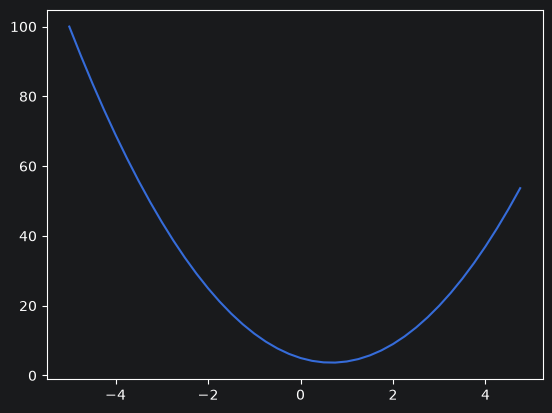

In [16]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs,ys)

In [17]:
h = 0.000001
x = 2/3
(f(x + h) - f(x))/h

2.999378523327323e-06

In [18]:
# more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [19]:
h = 0.0001
#inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c
print('d1', d1)
print('d2', d2)

print('slope', (d2 - d1) / h)





d1 4.0
d2 4.0001
slope 0.9999999999976694


In [20]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    def __repr__(self):
       return f"Value(data={self.data})"


    def __add__(self,other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    def __mul__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data,(self,other),'*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __pow__(self,other):
        assert isinstance(other, (int, float))
        out = Value(self.data**other, (self,),f'**{other}')

        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        return out

    def __rmul__(self ,other): # other * self
        return self * other
    def __truediv__(self,other):
        return self * other**-1
    def __neg__(self):
        return self * -1
    def __sub__(self,other):
        return self * (-other)
    def __radd__(self, other): # other + self
        return self + other



    def tanh(self):
        x = self.data
        t = (math.exp(x*2) - 1)/(math.exp(x*2) + 1)
        out = Value(t, (self , ), 'tanh')

        def _backward():
            self.grad += (1- t**2) * out.grad
        out._backward = _backward

        return out
    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self, ), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad  = 1.0
        for node in reversed(topo):
            node._backward()






In [21]:
a = Value(2.0)
b = Value(4.0)
a-b


Value(data=-8.0)

a / b
a * (1/b)
a * (b**-1)

In [22]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})

    for n in nodes:
        dot.node(name=str(id(n)), label = "{ data %.4f | grad %.4f }" % (n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=str(id(n)) + n._op, label=n._op)
            dot.edge(str(id(n)) + n._op, str(id(n)))

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [23]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f


print(L.data)


AttributeError: 'float' object has no attribute 'data'

In [ ]:
a.grad = -2.0 * 3.0
b.grad = -2.0 * 2.0

dL / de = -2.0

e = a * b
de / da

dL / da = (dL / de) - (de / da)

# L = d  * f
# dL/dd = 7 f
#
# ((d+h)*f - d*f/h)
# (s*f + b*f - d*f) / h
# (h*f)/h
# f

In [ ]:
L.grad = 1.0

dd / dc = 1.0
dd /de = 1.0
d = c + e

WANT:
dL / dc = (dL / dd) * (dd / dc)

KNOW:
dL / dd
dd/ dc






# (f(x+h) - f(x)) / h
# ((c+h + e) - (c + e)) / h
# (c + h + e - c - e)/h
# h/h
# 1.0


In [ ]:
def lol():
    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a*b; e.label='e'
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L.data

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    b.data += h
    e = a*b; e.label='e'
    c = Value(10.0, label='c')
    d = e + c; d.label='d'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L2 = L.data

    print((L2 - L1) / h)

lol()


In [ ]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [ ]:


# inputs x1 x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1,w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813753965432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label =  'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); label = 'o'
o.backward()



In [ ]:
draw_dot(o)

In [ ]:
# inputs x1 x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
# weights w1,w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
# bias of the neuron
b = Value(6.8813753965432,label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label =  'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'

e = (2*n).exp()
o = (e - 1) / (e + 1)
o.label = 'o'
o.backward()
draw_dot(o)

In [ ]:
import torch

In [ ]:

x1 = torch.Tensor([2.0]).double()            ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()            ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()           ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()            ; w2.requires_grad = True
b = torch.Tensor([6.8813753965432]).double() ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('_____')
print('x2',x2.grad.item())
print('w2',w2.grad.item())
print('x1',x1.grad.item())
print('w1',w1.grad.item())

In [ ]:
import random

In [ ]:
class Neuron:

    def __init__(self,nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self, x):
        # w * x + b
        act = sum((wi*xi for wi,xi in zip(self.w,x)) ,self.b)
        out = act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]
class Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self,nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

    def __call__(self,x):
            for layer in self.layers:
                x = layer(x)
            return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]



In [ ]:
x = [2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

In [ ]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0]
]
ys = [1.0,-1.0,-1.0,1.0] #desired targets
ypred = [n(x) for x in xs]
ypred

In [ ]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys,ypred))

    # backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k , loss.data)


In [ ]:


# PRACTICE OF MULTI LINEAR PERCEPTRON

import torch
import torch.nn as nn
import torch.optim as optim

device = ("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
X = torch.unsqueeze(torch.linspace(-3,3,200,device=device),dim=1)
y_true  = X.pow(2) + torch.randn(X.size(),device=device)

class NonLinearModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features=1, out_features=16),
            nn.ReLU(),
            nn.Linear(in_features=16,out_features=16),
            nn.ReLU(),
            nn.Linear(in_features=16,out_features=1)
        )

    def forward(self,x):
        return self.net(x)

model = NonLinearModel().to(device)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

epochs = 500
for epoch in range(epochs):
    y_pred = model(X)
    loss = criterion(y_pred,y_true)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}] | Loss: {loss.item():.4f}")

print("\n✅ MLP Model Successfully Trained on Non-Linear Quadratic Data!")





In [ ]:

# PRACTICE OF DATASET AND DATALOADER

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import  Dataset,DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class QuadraticDataset(Dataset):
    def __init__(self,num_samples=1000):
        super().__init__()
        self.x = torch.unsqueeze(torch.linspace(-3,3,200,device=device),dim=1)
        self.y = self.x.pow(2) + torch.randn(self.x.size(),device=device) * 0.2

    def __len__(self):
        return len(self.x)
    def __getitem__(self, index):
        return self.x[index], self.y[index]


dataset = QuadraticDataset(num_samples=1000)
train_loader = DataLoader(dataset=dataset,batch_size=32,shuffle=True)

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features=1, out_features=16),
            nn.ReLU(),
            nn.Linear(in_features=16,out_features=16),
            nn.ReLU(),
            nn.Linear(in_features=16,out_features=1)

        )
    def forward(self,x):
        return self.net(x)

model = MLP().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.MSELoss()

epochs = 20
print(f"Training on {len(dataset)} samples across {len(train_loader)} batches per epoch...\n")
for epoch in range(epochs):
    epoch_loss = 0

    for batch_x , batch_y in train_loader:
        batch_x , batch_y = batch_x.to(device) , batch_y.to(device)
        prediction = model(batch_x)
        loss = criterion(prediction, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * batch_x.size(0)

    avg_loss = epoch_loss / len(train_loader)

    if (epoch + 1) % 5 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}] | Avg Loss: {avg_loss:.4f}")

print("\n✅ Mini-batch training completed successfully!")



In [ ]:

# PRACTICE OF CONVOLUTIONAL NEURAL NETWORK

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.1307,), (0.1307,))]
)

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, transform=transform, download=True)

test_dataset = torchvision.datasets.MNIST(root='./data', train=False, transform=transform , download=True)

train_loader = torch.utils.data.DataLoader(dataset=train_dataset,batch_size=64,shuffle=True)
test_loader = torch.utils.data.DataLoader(dataset=test_dataset,batch_size=64,shuffle=True)

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(7 * 7 * 32, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x
model = SimpleCNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

epochs = 3
for epoch in range(epochs):
    model.train()
    running_loss = 0
    for images , labels in train_loader:
        images , labels = images.to(device) , labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch + 1}/{epochs}] | Loss: {running_loss / len(train_loader):.4f}")


model.eval()
correct , total = 0,0
with torch.no_grad():
    for images , labels in test_loader:
        images , labels = images.to(device) , labels.to(device)
        outputs = model(images)
        _ , predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
print(f"\n Accuracy on Test Set: {100 * correct / total:.2f}%")





In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset,DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device {device}")

corpus = [
    ("i loved this movie it was awesome", 1),
    ("fantastic acting and great plot", 1),
    ("highly recommend this masterclass film", 1),
    ("truly brilliant and inspiring storyline", 1),
    ("terrible movie waste of time and money", 0),
    ("horrible script bad acting awful experience", 0),
    ("boring predictable and complete disappointment", 0),
    ("worst film ever created useless attempt", 0)
]

vocab = {"<PAD>" : 0 ,"<UNK>" : 1}
for sentence , _ in corpus:
    for word in sentence.split():
        if word not in vocab:
            vocab[word] = len(vocab)

vocab_size = len(vocab)
max_seq_length = 8

def encoded_sentence(sentence,vocab,max_len):
    tokens = [vocab.get(word, vocab["<UNK>"]) for word in sentence.split()]
    if len(tokens) < max_len:
        tokens += [vocab["<PAD>"]] * (max_len - len(tokens))
    else:
        tokens = tokens[:max_len]
    return tokens

class TextDataset(Dataset):
    def __init__(self, corpus, vocab, max_len):
        self.data = []
        self.labels = []
        for text, label in corpus:
            self.data.append(encoded_sentence(text, vocab, max_len))
            self.labels.append(label)


        self.data = torch.tensor(self.data, dtype=torch.long)
        self.labels = torch.tensor(self.labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)
    def __getitem__(self,idx):
        return self.data[idx] , self.labels[idx]

dataset = TextDataset(corpus,vocab,max_seq_length)
train_loader = DataLoader(dataset,batch_size=2,shuffle=True)

class SentimentLSTM(nn.Module):
    def __init__(self,vocab_size,embed_dim,hidden_dim,output_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size,embed_dim,padding_idx=0)
        self.lstm = nn.LSTM(embed_dim,hidden_dim,batch_first=True)
        self.fc = nn.Linear(hidden_dim,output_dim)

    def forward(self, x):
        embedded = self.embedding(x)
        _, (hidden, _) = self.lstm(embedded)
        out = self.fc(hidden.squeeze(0))
        return out
embed_size = 16
hidden_dim = 32
output_dim = 2

model = SentimentLSTM(vocab_size,embed_size,hidden_dim,output_dim).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr=0.01)

epochs = 30
print(f"\nTraining Text Classification LSTM (Vocab Size: {vocab_size})...\n")
for epoch in range(epochs):
    model.train()
    total_loss = 0
    for x_batch , y_batch in train_loader:
        x_batch , y_batch = x_batch.to(device) , y_batch.to(device)


        outputs = model(x_batch)
        loss = criterion(outputs,y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}] | Loss: {total_loss / len(train_loader):.4f}")

model.eval()
test_sentences = [
    "awesome script and brilliant movie",
    "terrible waste and awful experience"
]
print("\n--- Model Predictions ---")
with torch.no_grad():
    for text in test_sentences:
        encoded = torch.tensor([encoded_sentence(text,vocab,max_seq_length)]).to(device)
        output = model(encoded)
        prediction = torch.argmax(output,dim=1).item()
        label_str = "Positive 😊" if prediction == 1 else "Negative 😞"
        print(f"Sentence: '{text}' --> Prediction: {label_str}")





In [ ]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load Pretrained Tokenizer & Model
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name).to(device)

# 2. Contextual Sentences (The word "bank" has different meanings)
sentences = [
    "I deposited money in the bank",
    "We sat on the river bank"
]

# 3. Tokenize with Batch Padding & Tensors
inputs = tokenizer(
    sentences,
    padding=True,
    truncation=True,
    return_tensors="pt"
).to(device)

print("Input IDs Tensor Shape:", inputs["input_ids"].shape)
print("Attention Mask Shape:", inputs["attention_mask"].shape)

# 4. Extract BERT Contextual Embeddings
model.eval()
with torch.no_grad():
    outputs = model(**inputs)

# outputs.last_hidden_state contains the contextual vectors for every token!
last_hidden_state = outputs.last_hidden_state
print("Last Hidden State Shape:", last_hidden_state.shape)

In [1]:
import torch
from  torch.utils.data import Dataset,DataLoader
from transformers import AutoTokenizer,AutoModelForSequenceClassification

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using Device {device}")

model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
train_texts = [
    "Great movie, loved every second!",
    "It was okay, nothing special.",
    "Terrible experience, complete waste of time.",
    "Brilliant performance and awesome plot!",
    "An average film, neither bad nor good.",
    "Horrible script and awful acting."
]

train_labels = [2,1,0,2,1,0]

class SentimentDataset(Dataset):
    def __init__(self,texts,labels,tokenizer,max_len=32):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        encoding = tokenizer(text , truncation=True,padding="max_length",return_tensors="pt")
        return {"input_ids": encoding["input_ids"].flatten(), "attention_mask": encoding["attention_mask"].flatten(),"labels": torch.tensor(label,dtype=torch.long)}

dataset = SentimentDataset(train_texts,train_labels,tokenizer)
dataloader = DataLoader(dataset,batch_size=2,shuffle=True)

model = AutoModelForSequenceClassification.from_pretrained(model_name,num_labels=3).to(device)
optimizer = torch.optim.AdamW(model.parameters(),lr=2e-5)

epochs = 12
print("\n START BERT FINE TUNING ")
model.train()
for epoch in range(epochs):
    total_loss = 0.0
    for batch in dataloader:
        optimizer.zero_grad()

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids=input_ids,attention_mask=attention_mask,labels=labels)
        loss = outputs.loss

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(dataloader)
    print(f"Epoch [{epoch + 1}/{epochs}] | Loss: {avg_loss:.4f}")

model.eval()
test_sentences = [
    "Awesome cinematography and fantastic story",
    "It was an acceptable and average movie",
    "Worst film ever made, complete garbage"
]

id2label = {0: "Negative 😞", 1: "Neutral 😐", 2: "Positive 😊"}

print("\n--- Model Predictions ---")
with torch.no_grad():
    for text in test_sentences:
        inputs = tokenizer(text,return_tensors="pt",truncation=True,padding=True).to(device)
        outputs = model(**inputs)
        logits = outputs.logits
        pred_idx = torch.argmax(logits , dim=1).item()

        print(f"Sentence: '{text}' --> Prediction: {id2label[pred_idx]}")


/home/krishna/PycharmProjects/Deep_Learning/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using Device cuda


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10104.92it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo


 START BERT FINE TUNING 
Epoch [1/12] | Loss: 1.2421
Epoch [2/12] | Loss: 1.0408
Epoch [3/12] | Loss: 0.9213
Epoch [4/12] | Loss: 0.8063
Epoch [5/12] | Loss: 0.7089
Epoch [6/12] | Loss: 0.6849
Epoch [7/12] | Loss: 0.5270
Epoch [8/12] | Loss: 0.5573
Epoch [9/12] | Loss: 0.4580
Epoch [10/12] | Loss: 0.4054
Epoch [11/12] | Loss: 0.3840
Epoch [12/12] | Loss: 0.3517

--- Model Predictions ---
Sentence: 'Awesome cinematography and fantastic story' --> Prediction: Positive 😊
Sentence: 'It was an acceptable and average movie' --> Prediction: Neutral 😐
Sentence: 'Worst film ever made, complete garbage' --> Prediction: Negative 😞


In [ ]:
import os
import torch
import torch.nn as nn

# 1. Setup Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", device)

# 2. Define a Simple Classification Model
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim=10, num_classes=3):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# 3. Instantiate Model and Generate Dummy Data
torch.manual_seed(42)
original_model = SimpleClassifier().to(device)
original_model.eval()

# Sample input vector shape: (1 batch, 10 features)
sample_input = torch.randn(1, 10).to(device)

# Get baseline prediction prior to saving
with torch.no_grad():
    original_output = original_model(sample_input)

print("\n--- Baseline Forward Pass ---")
print("Original Model Output Logits:", original_output)

# 4. Save State Dict (Weights & Biases) to Disk
os.makedirs("models", exist_ok=True)
save_path = "models/simple_classifier_weights.pth"

torch.save(original_model.state_dict(), save_path)
print(f"\n✅ Model state_dict successfully saved to: '{save_path}'")

# 5. Load State Dict into a Fresh Model Instance
# Step A: Instantiate the blank architecture
loaded_model = SimpleClassifier().to(device)

# Step B: Load the dictionary checkpoint from disk
state_dict = torch.load(save_path, map_location=device)

# Step C: Inject learned parameters into the fresh model
loaded_model.load_state_dict(state_dict)
loaded_model.eval()

# 6. Verify Predictions Match Identically
with torch.no_grad():
    loaded_output = loaded_model(sample_input)

print("\n--- Verification After Reloading ---")
print("Loaded Model Output Logits:  ", loaded_output)

# Check exact equality across output tensors
are_equal = torch.allclose(original_output, loaded_output)
print(f"\nOutputs Match Identically? -> {are_equal} 🎉")

In [ ]:
import torch
import torch.nn as nn

# 1. Define Model Architecture
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim=10, num_classes=3):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 32)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

# 2. Instantiate Model and Set to Evaluation Mode
model = SimpleClassifier()
model.eval()

# 3. Create Dummy Input (Matching input shape: batch_size=1, features=10)
dummy_input = torch.randn(1, 10)

# 4. Export to ONNX Format
onnx_file_path = "models/simple_classifier.onnx"

torch.onnx.export(
    model,                      # Model being exported
    dummy_input,                # Model input (or tuple for multiple inputs)
    onnx_file_path,             # File path where model is saved
    export_params=True,         # Store trained weights inside the model file
    opset_version=11,           # ONNX operator set version to target
    do_constant_folding=True,   # Optimize constant expressions in graph
    input_names=['input'],      # Input tensor naming
    output_names=['output'],    # Output tensor naming
    dynamic_axes={              # Allow flexible batch sizes at runtime
        'input': {0: 'batch_size'},
        'output': {0: 'batch_size'}
    }
)

print(f"✅ Model exported successfully to ONNX: '{onnx_file_path}'")

In [ ]:
from fastapi import FastAPI
app = FastAPI()
@app.get("/health")
def health():
    return {"status": "healthy"}

